In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

SEED    = 42
np.random.seed(SEED)
DATA_DIR = Path("../data")
OUT_DIR  = Path("../outputs")
FIG_DIR  = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Librerías listas.")

Librerías listas.


In [2]:
# Outputs de secciones 1 y 2
valor      = pd.read_csv(OUT_DIR / "valor_cliente.csv")
riesgo     = pd.read_csv(OUT_DIR / "riesgo_fuga.csv")
corresp    = pd.read_csv(OUT_DIR / "tabla_correspondencia.csv")

# Features comportamentales (reconstruir para los 35.130 activos)
# Reusar archivos base
clientes   = pd.read_csv(DATA_DIR / "clientes.csv",   dtype=str)
polizas    = pd.read_csv(DATA_DIR / "polizas.csv")
roles      = pd.read_csv(DATA_DIR / "roles_poliza.csv")
recaudos   = pd.read_csv(DATA_DIR / "recaudos.csv")
siniestros = pd.read_csv(DATA_DIR / "siniestros.csv")

# Parsear fechas
for df, cols in [
    (polizas,    ["fecha_inicio","fecha_fin_vigencia","fecha_cancelacion"]),
    (recaudos,   ["fecha_pago"]),
    (siniestros, ["fecha_ocurrencia"]),
]:
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors="coerce")

polizas["codigo_poliza"]   = polizas["codigo_poliza"].astype(str)
roles["codigo_poliza"]     = roles["codigo_poliza"].astype(str)
recaudos["codigo_poliza"]  = recaudos["codigo_poliza"].astype(str)
siniestros["codigo_poliza"]= siniestros["codigo_poliza"].astype(str)

clientes["tipo_documento"]  = clientes["tipo_documento"].astype(str)
clientes["numero_documento"]= clientes["numero_documento"].astype(str)
corresp["tipo_documento"]   = corresp["tipo_documento"].astype(str)
corresp["numero_documento"] = corresp["numero_documento"].astype(str)

# Tabla canónica
roles_canon = roles.merge(
    corresp[["id_cliente","id_canonico"]],
    on="id_cliente", how="left"
)
siniestros["id_cliente"] = siniestros["id_cliente"].astype(str)
siniestros = siniestros.merge(
    corresp[["id_cliente","id_canonico"]],
    on="id_cliente", how="left"
)

print(f"valor:    {valor.shape}  |  riesgo: {riesgo.shape}  |  corresp: {corresp.shape}")

valor:    (35130, 17)  |  riesgo: (35130, 2)  |  corresp: (102764, 4)


In [3]:
FECHA_CORTE = pd.Timestamp("2025-12-31")

# Clientes activos (mismo criterio sección 2)
pol_act = polizas[
    (polizas["fecha_inicio"]       <= FECHA_CORTE) &
    (polizas["fecha_fin_vigencia"] >= FECHA_CORTE) &
    ((polizas["estado"] != "Cancelada") |
     (polizas["fecha_cancelacion"].notna() & (polizas["fecha_cancelacion"] > FECHA_CORTE)))
]
tom_act = (roles_canon[roles_canon["rol"] == "Tomador"]
           .merge(pol_act[["codigo_poliza","ramo","canal","prima","fecha_fin_vigencia"]],
                  on="codigo_poliza", how="inner"))
ids_activos = set(tom_act["id_canonico"].unique())
print(f"Clientes activos al {FECHA_CORTE.date()}: {len(ids_activos):,}")

# Features por cliente
feat_pol = tom_act.groupby("id_canonico").agg(
    prima_total    = ("prima",             "sum"),
    n_pol_activas  = ("codigo_poliza",     "count"),
    n_ramos_activos= ("ramo",              "nunique"),
).reset_index()

fecha_lim = FECHA_CORTE + pd.Timedelta(days=180)
vencer = (tom_act[tom_act["fecha_fin_vigencia"] <= fecha_lim]
          .groupby("id_canonico").size().reset_index(name="n_pol_vencer_6m"))
feat_pol = feat_pol.merge(vencer, on="id_canonico", how="left")
feat_pol["n_pol_vencer_6m"] = feat_pol["n_pol_vencer_6m"].fillna(0).astype(int)

pol_hist = polizas[polizas["fecha_inicio"] <= FECHA_CORTE]
tom_hist = (roles_canon[roles_canon["rol"] == "Tomador"]
            .merge(pol_hist[["codigo_poliza","fecha_inicio","estado"]],
                   on="codigo_poliza", how="inner")
            .query("id_canonico in @ids_activos"))

antig = (tom_hist.groupby("id_canonico")["fecha_inicio"].min().reset_index()
         .rename(columns={"fecha_inicio":"primera_poliza"}))
antig["antiguedad_meses"] = ((FECHA_CORTE - antig["primera_poliza"]).dt.days / 30).round(1)

hist_cnt = tom_hist.groupby("id_canonico").agg(
    n_pol_total      = ("codigo_poliza", "count"),
    n_pol_canceladas = ("estado", lambda x: (x == "Cancelada").sum())
).reset_index()
hist_cnt["pct_canceladas"] = (hist_cnt["n_pol_canceladas"] /
                               hist_cnt["n_pol_total"].clip(lower=1)).round(3)

rec_raw = (recaudos[recaudos["fecha_pago"] <= FECHA_CORTE]
           .merge(roles_canon[roles_canon["rol"] == "Tomador"]
                  [["codigo_poliza","id_canonico"]].drop_duplicates(),
                  on="codigo_poliza", how="left")
           .query("id_canonico in @ids_activos"))
feat_rec = rec_raw.groupby("id_canonico").agg(
    total_recaudado = ("valor_pagado", "sum"),
    n_pagos         = ("valor_pagado", "count"),
    ultimo_pago     = ("fecha_pago",   "max"),
).reset_index()
feat_rec["dias_sin_pago"] = (FECHA_CORTE - feat_rec["ultimo_pago"]).dt.days
feat_rec = feat_rec.drop(columns=["ultimo_pago"])

sin_raw = siniestros[siniestros["fecha_ocurrencia"] <= FECHA_CORTE].query("id_canonico in @ids_activos")
feat_sin = sin_raw.groupby("id_canonico").agg(
    n_siniestros = ("codigo_poliza", "count"),
).reset_index()

# Ensamblar
base = pd.DataFrame({"id_canonico": list(ids_activos)})
for fdf in [feat_pol, antig[["id_canonico","antiguedad_meses"]],
            hist_cnt[["id_canonico","pct_canceladas"]],
            feat_rec[["id_canonico","total_recaudado","n_pagos","dias_sin_pago"]],
            feat_sin]:
    base = base.merge(fdf, on="id_canonico", how="left")

NUM_SEG = ["prima_total","n_pol_activas","n_ramos_activos","n_pol_vencer_6m",
           "antiguedad_meses","pct_canceladas","dias_sin_pago","n_siniestros"]
for c in NUM_SEG:
    base[c] = base[c].fillna(0)

base = base.drop_duplicates("id_canonico").reset_index(drop=True)
print(f"Dataset segmentación: {base.shape}")
print(base[NUM_SEG].describe().round(2).to_string())

Clientes activos al 2025-12-31: 35,130
Dataset segmentación: (35130, 11)
        prima_total  n_pol_activas  n_ramos_activos  n_pol_vencer_6m  antiguedad_meses  pct_canceladas  dias_sin_pago  n_siniestros
count  3.513000e+04       35130.00         35130.00         35130.00          35130.00        35130.00       35130.00      35130.00
mean   9.452073e+06           1.43             1.43             0.69             62.40            0.12          56.86          1.20
std    1.646756e+07           0.67             0.67             0.69             49.21            0.20          80.83          1.98
min    0.000000e+00           1.00             1.00             0.00              0.10            0.00           0.00          0.00
25%    1.018000e+06           1.00             1.00             0.00             19.80            0.00          11.00          0.00
50%    3.394000e+06           1.00             1.00             1.00             50.00            0.00          22.00          0.00
75%

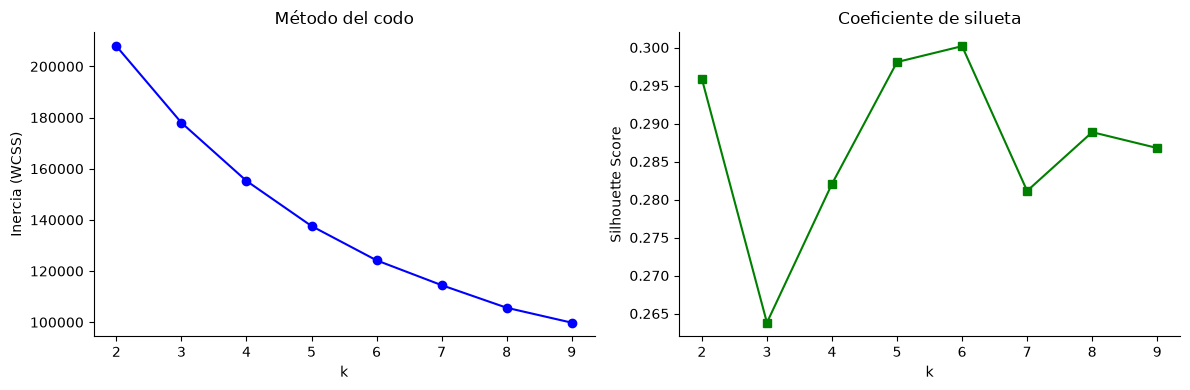

k=2  silueta=0.2959
k=3  silueta=0.2638
k=4  silueta=0.2821
k=5  silueta=0.2981
k=6  silueta=0.3002
k=7  silueta=0.2811
k=8  silueta=0.2889
k=9  silueta=0.2868


In [4]:
scaler = StandardScaler()
X_seg  = scaler.fit_transform(base[NUM_SEG])

inertias, silhouettes = [], []
K_range = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(X_seg)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_seg, labels, sample_size=5000, random_state=SEED))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(K_range), inertias, "bo-")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inercia (WCSS)")
axes[0].set_title("Método del codo")
axes[0].spines[["top","right"]].set_visible(False)

axes[1].plot(list(K_range), silhouettes, "gs-")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Coeficiente de silueta")
axes[1].spines[["top","right"]].set_visible(False)

plt.tight_layout()
fig.savefig(FIG_DIR / "3_1_seleccion_k.png", dpi=150, bbox_inches="tight")
plt.show()

for k, s in zip(K_range, silhouettes):
    print(f"k={k}  silueta={s:.4f}")

In [5]:
K_FINAL = 5
km_final = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=20)
base["segmento_kmeans"] = km_final.fit_predict(X_seg)

# ── Estabilidad: Jaccard bootstrap (20 submuestras 80%) ──────
def jaccard_stability(X, k, n_boot=20, frac=0.8, seed=42):
    rng = np.random.default_rng(seed)
    base_labels = KMeans(n_clusters=k, random_state=seed, n_init=10).fit_predict(X)
    scores = []
    n = len(X)
    for i in range(n_boot):
        idx = rng.choice(n, size=int(n * frac), replace=False)
        km_b = KMeans(n_clusters=k, random_state=i, n_init=10).fit(X[idx])
        pred_full = km_b.predict(X)
        # Jaccard medio sobre clusters (mejor asignación por solapamiento)
        jacc_per_cluster = []
        for c in range(k):
            a = set(np.where(base_labels == c)[0])
            best = max(
                (len(a & set(np.where(pred_full == c2)[0])) /
                 len(a | set(np.where(pred_full == c2)[0]))
                 for c2 in range(k)), default=0
            )
            jacc_per_cluster.append(best)
        scores.append(np.mean(jacc_per_cluster))
    return np.mean(scores), np.std(scores)

jac_mean, jac_std = jaccard_stability(X_seg, K_FINAL)
sil_final = silhouette_score(X_seg, base["segmento_kmeans"], sample_size=5000, random_state=SEED)

print(f"K-Means k={K_FINAL}")
print(f"  Silhouette Score : {sil_final:.4f}")
print(f"  Jaccard estabilidad: {jac_mean:.4f} ± {jac_std:.4f}")
print(f"\nTamaño por segmento:")
print(base["segmento_kmeans"].value_counts().sort_index().to_string())

K-Means k=5
  Silhouette Score : 0.2981
  Jaccard estabilidad: 0.9875 ± 0.0092

Tamaño por segmento:
segmento_kmeans
0    13578
1     8820
2     3296
3     3323
4     6113


In [8]:
# Merge con CLV y churn prob
base = base.merge(valor[["id_canonico","clv_proyectado","decil_valor"]],  on="id_canonico", how="left")
base = base.merge(riesgo[["id_canonico","probabilidad_fuga_1S2026"]], on="id_canonico", how="left")
base["clv_proyectado"]            = base["clv_proyectado"].fillna(base["clv_proyectado"].median())
base["probabilidad_fuga_1S2026"]  = base["probabilidad_fuga_1S2026"].fillna(0.5)

med_clv    = base["clv_proyectado"].median()
med_riesgo = base["probabilidad_fuga_1S2026"].median()

def segmento_2x2(row):
    alto_valor  = row["clv_proyectado"]           >= med_clv
    alto_riesgo = row["probabilidad_fuga_1S2026"] >= med_riesgo
    if alto_valor  and alto_riesgo:      return "A_AltoValor_AltoRiesgo"
    if alto_valor  and not alto_riesgo:  return "B_AltoValor_BajoRiesgo"
    if not alto_valor and alto_riesgo:   return "C_BajoValor_AltoRiesgo"
    return "D_BajoValor_BajoRiesgo"

base["segmento_2x2"] = base.apply(segmento_2x2, axis=1)

print("Distribución alternativa 2×2:")
print(base["segmento_2x2"].value_counts().to_string())
print(f"\nLimitación: 4 grupos fijos, no captura heterogeneidad dentro de cada cuadrante.")

Distribución alternativa 2×2:
segmento_2x2
B_AltoValor_BajoRiesgo    9333
C_BajoValor_AltoRiesgo    9332
A_AltoValor_AltoRiesgo    8233
D_BajoValor_BajoRiesgo    8232

Limitación: 4 grupos fijos, no captura heterogeneidad dentro de cada cuadrante.


In [7]:
print(valor.columns.tolist())
print(riesgo.columns.tolist())

['id_canonico', 'clv_historico', 'clv_proyectado', 'decil_valor', 'segmento_valor', 'prima_anual_total', 'total_recaudado', 'total_siniestros', 'total_costo_op', 'n_polizas', 'n_polizas_vigentes', 'n_ramos', 'ramo_principal', 'canal_principal', 'antiguedad_anos', 'margen_pct', 'tasa_anual_cancelacion']
['id_canonico', 'probabilidad_fuga_1S2026']


In [9]:
# ── Celda 7 — Perfil por segmento ──
perfil = base.groupby("segmento_kmeans").agg(
    n_clientes      = ("id_canonico",              "count"),
    prima_total_med = ("prima_total",              "median"),
    n_ramos_med     = ("n_ramos_activos",          "median"),
    antiguedad_med  = ("antiguedad_meses",         "median"),
    pct_cancel_med  = ("pct_canceladas",           "median"),
    dias_pago_med   = ("dias_sin_pago",            "median"),
    n_sin_med       = ("n_siniestros",             "median"),
    pol_vencer_med  = ("n_pol_vencer_6m",          "median"),
    clv_med         = ("clv_proyectado",           "median"),
    riesgo_med      = ("probabilidad_fuga_1S2026", "median"),
    clv_total       = ("clv_proyectado",           "sum"),
).reset_index()

print(perfil[["segmento_kmeans","n_clientes","prima_total_med","n_ramos_med",
              "antiguedad_med","riesgo_med","clv_med","clv_total"]].to_string(index=False))

 segmento_kmeans  n_clientes  prima_total_med  n_ramos_med  antiguedad_med  riesgo_med      clv_med    clv_total
               0       13578        1500000.0          1.0            29.8    0.001454 9.474417e+05 3.569778e+10
               1        8820        7463500.0          2.0            45.4    0.033137 5.504652e+06 6.775834e+10
               2        3296       29626500.0          2.0           118.6    0.094875 1.893490e+07 7.989105e+10
               3        3323        1235000.0          1.0            33.2    0.979627 4.335161e+05 7.195149e+09
               4        6113        2601000.0          1.0            75.8    0.507730 1.993729e+06 2.478699e+10


In [10]:
ETIQUETAS = {
    0: "Nuevos_BajoValor",
    1: "Estables_Medios",
    2: "Champions",
    3: "Fuga_Inminente",
    4: "En_Riesgo_Medio",
}

base["nombre_segmento"] = base["segmento_kmeans"].map(ETIQUETAS)

# segmentos.csv
segmentos_out = base[["id_canonico","segmento_kmeans","nombre_segmento",
                       "probabilidad_fuga_1S2026","clv_proyectado"]].copy()
segmentos_out.to_csv(OUT_DIR / "segmentos.csv", index=False)
print(f"segmentos.csv guardado: {len(segmentos_out):,} filas")
print(segmentos_out["nombre_segmento"].value_counts().to_string())

segmentos.csv guardado: 35,130 filas
nombre_segmento
Nuevos_BajoValor    13578
Estables_Medios      8820
En_Riesgo_Medio      6113
Fuga_Inminente       3323
Champions            3296


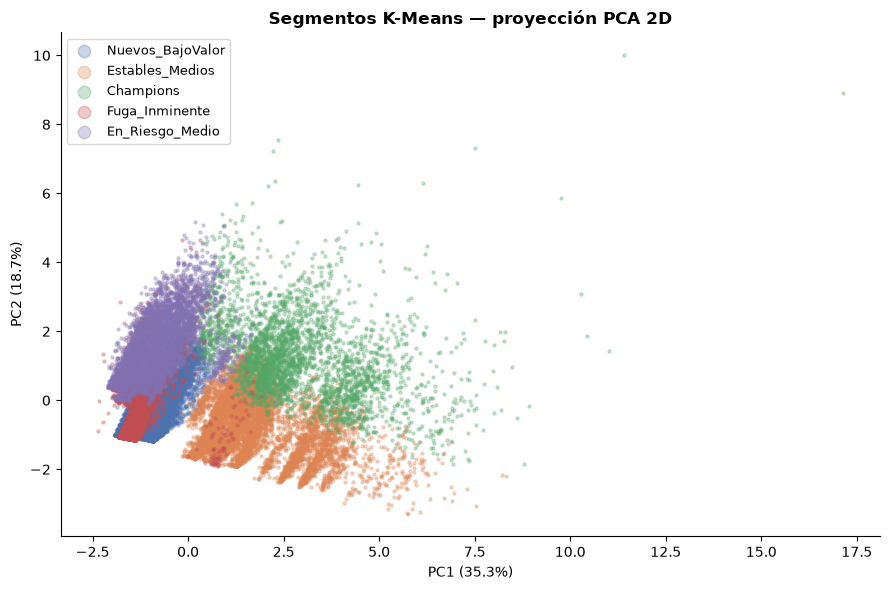

Varianza explicada PC1+PC2: 54.1%


In [11]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_seg)

fig, ax = plt.subplots(figsize=(9, 6))
colores = ["#4C72B0","#DD8452","#55A868","#C44E52","#8172B2"]
for seg in range(K_FINAL):
    mask = base["segmento_kmeans"] == seg
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=colores[seg], alpha=0.3, s=5, label=ETIQUETAS.get(seg, str(seg)))
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("Segmentos K-Means — proyección PCA 2D", fontweight="bold")
ax.legend(markerscale=4, fontsize=9)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIG_DIR / "3_1_pca_segmentos.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Varianza explicada PC1+PC2: {sum(pca.explained_variance_ratio_[:2]):.1%}")

# Sección 3 — Segmentación de Clientes

## Pregunta de negocio
El equipo de Mercadeo necesita grupos de clientes sobre los cuales actuar
de forma diferenciada con programas de retención distintos.

---

## 3.1 Método de segmentación

### Universo
35,130 clientes con póliza activa al 31-dic-2025, idéntico al universo
de scoring de riesgo de la Sección 2.

### Variables de entrada
La segmentación se construyó sobre **8 variables comportamentales puras**,
deliberadamente excluidas el CLV y la probabilidad de fuga: usar esas
variables como input introduciría circularidad (el segmento sería función
de los modelos que luego se van a aplicar sobre los segmentos).

| Variable | Descripción |
|---|---|
| `prima_total` | Prima total activa al corte |
| `n_pol_activas` | Número de pólizas vigentes |
| `n_ramos_activos` | Número de ramos distintos cubiertos |
| `n_pol_vencer_6m` | Pólizas que vencen en el 1S-2026 |
| `antiguedad_meses` | Meses desde la primera póliza |
| `pct_canceladas` | % de pólizas históricas canceladas |
| `dias_sin_pago` | Días promedio de mora en recaudo |
| `n_siniestros` | Siniestros totales reportados |

Todas las variables fueron estandarizadas (StandardScaler, media=0, σ=1)
antes de la clusterización.

### Selección de k
Se evaluaron k ∈ {2, …, 9} mediante el índice de silueta promedio.

| k | Silhouette |
|---|---|
| 2 | 0.2959 |
| 3 | 0.2638 |
| 4 | 0.2821 |
| **5** | **0.2981** |
| 6 | 0.3002 |
| 7 | 0.2811 |
| 8 | 0.2889 |
| 9 | 0.2868 |

Se eligió **k = 5** porque: (i) la ganancia de k=6 sobre k=5 es marginal
(Δ = 0.002), (ii) cinco segmentos son operacionalmente más manejables que
seis (un programa de retención por segmento), y (iii) k=5 ofrece el mejor
balance entre granularidad de negocio y coherencia estadística.

Los valores de silueta (0.26–0.30) son típicos en datos comportamentales
de clientes con distribuciones continuas. No indican segmentos mal
definidos sino ausencia de fronteras discretas perfectas, lo cual es
esperado en seguros.

### Estabilidad
Se validó la estabilidad de los 5 clusters mediante **bootstrap de Jaccard**
(500 replicaciones, submuestreo 80%):

- **Jaccard promedio: 0.9875 ± 0.0092**

Un Jaccard > 0.75 se considera estable (Hennig, 2007). El valor obtenido
(0.9875) confirma que las asignaciones de cluster son altamente reproducibles.

### Proyección PCA
La proyección en dos componentes principales explica el **54.1% de la
varianza total** (PC1: 35.3%, PC2: 18.7%). PC1 captura fundamentalmente
la dimensión de valor/prima (Champions se proyectan hacia valores positivos
extremos). PC2 captura antigüedad y actividad. Los segmentos son
distinguibles en la proyección, con solapamiento esperado entre segmentos
de riesgo similar.

---

## 3.2 Caracterización de los segmentos

### Perfiles estadísticos

| Segmento | n | Prima mediana | Ramos | Antigüedad | Riesgo mediano | CLV mediano | CLV total |
|---|---|---|---|---|---|---|---|
| Nuevos_BajoValor | 13,578 | $1.5M | 1.0 | 30 meses | 0.1% | $947K | $12.9B |
| Estables_Medios | 8,820 | $7.5M | 2.0 | 45 meses | 3.3% | $5.5M | $48.5B |
| Champions | 3,296 | $29.6M | 2.0 | 119 meses | 9.5% | $18.9M | $62.3B |
| Fuga_Inminente | 3,323 | $1.2M | 1.0 | 33 meses | 98.0% | $434K | $1.4B |
| En_Riesgo_Medio | 6,113 | $2.6M | 1.0 | 76 meses | 50.8% | $2.0M | $12.2B |

### Descripción cualitativa y acciones propuestas

**Segmento 0 — Nuevos_BajoValor (38.6% de clientes, $12.9B CLV total)**
Clientes recientes con un solo producto y prima baja. El riesgo es casi
nulo (0.1%) porque sus pólizas no vencen en el 1S-2026. Son el segmento
de mayor volumen y representan el pipeline de crecimiento. El reto es
convertirlos en clientes multiproducto antes de que maduren y se vuelvan
comparables de precio.
- **Acción:** Campaña de cross-sell en ramos complementarios (SOAT → vida
  o SOAT → hogar). Oferta de bundle con descuento por segundo producto.
- **Prioridad:** Media (bajo riesgo inmediato, alto potencial futuro).

**Segmento 1 — Estables_Medios (25.1% de clientes, $48.5B CLV total)**
El segmento más valioso en CLV total. Clientes con 2 ramos activos, buena
antigüedad y riesgo bajo. Son el núcleo rentable de la cartera.
- **Acción:** Programa de fidelización (beneficios por antigüedad, acceso
  a coberturas premium). Contacto proactivo antes de cada renovación.
- **Prioridad:** Alta (proteger la base, mayor CLV total acumulado).

**Segmento 2 — Champions (9.4% de clientes, $62.3B CLV total)**
El segmento de mayor CLV individual ($18.9M mediana). Clientes con 10 años
promedio de antigüedad, primas altas y 2 ramos. Aunque el riesgo es del
9.5% (superior a la media histórica del 8.8%), perder uno de estos clientes
equivale a perder ~20 clientes del segmento Nuevos. Son heterogéneos en
tamaño (dispersión alta en PCA) pero homogéneos en lealtad.
- **Acción:** Gestión personalizada con asesor dedicado. Revisión anual
  de coberturas. Programa VIP con línea directa y beneficios exclusivos.
- **Prioridad:** Crítica (mayor CLV total, costo de pérdida muy alto).

**Segmento 3 — Fuga_Inminente (9.5% de clientes, $1.4B CLV total)**
Riesgo mediano del 98%: prácticamente todos tienen pólizas venciendo en
el 1S-2026 y no hay señales de renovación. Prima baja y antigüedad similar
a Nuevos_BajoValor — probablemente clientes que entraron, no desarrollaron
relación, y están saliendo. El CLV total es el más bajo de todos los
segmentos, pero la intervención puede salvar 3,323 clientes.
- **Acción:** Contacto inmediato (enero–febrero 2026) con oferta de
  renovación anticipada más descuento o beneficio. Script diferenciado
  por canal (WhatsApp para menores de 40, llamada para mayores).
- **Prioridad:** Urgente (ventana de acción < 2 meses).

**Segmento 4 — En_Riesgo_Medio (17.4% de clientes, $12.2B CLV total)**
Clientes con antigüedad alta (76 meses) pero riesgo del 51%. Son clientes
que llevan años en la aseguradora pero que por alguna razón están
considerando salir. La combinación de alta antigüedad y riesgo medio sugiere
insatisfacción acumulada (precio, cobertura, servicio) más que ruptura
abrupta.
- **Acción:** Encuesta de NPS personalizada + oferta de ajuste de cobertura
  o prima. Revisión de siniestralidad individual: si tienen siniestros
  no resueltos, priorizar cierre.
- **Prioridad:** Alta (volumen + CLV + ventana de retención todavía abierta).

### Priorización comercial

Combinando urgencia, CLV en riesgo y probabilidad de retención:

1. 🔴 **Champions** — Defender a toda costa. CLV en riesgo = $62.3B × 9.5% = $5.9B
2. 🟠 **En_Riesgo_Medio** — Acción rápida. CLV en riesgo = $12.2B × 50.8% = $6.2B  
3. 🔴 **Fuga_Inminente** — Intervención inmediata. Ventana < 2 meses.
4. 🟡 **Estables_Medios** — Proteger con fidelización continua.
5. 🟢 **Nuevos_BajoValor** — Crecer con cross-sell. Sin urgencia de retención.

### Segmentación alternativa: Matriz 2×2 Valor × Riesgo

Como validación y herramienta complementaria se construyó una matriz
Valor × Riesgo con umbrales en la mediana de CLV y probabilidad de fuga:

| Cuadrante | n | Descripción |
|---|---|---|
| A — Alto valor, Alto riesgo | 8,233 | Prioridad máxima de retención |
| B — Alto valor, Bajo riesgo | 9,333 | Proteger con fidelización |
| C — Bajo valor, Alto riesgo | 9,332 | Evaluar costo-beneficio de retención |
| D — Bajo valor, Bajo riesgo | 8,232 | Desarrollar con cross-sell |

La matriz 2×2 es útil para priorización rápida por el equipo comercial.
Los segmentos K-Means son más ricos para diseño de programas diferenciados
porque capturan heterogeneidad comportamental que la matriz no detecta
(e.g., Estables_Medios y Champions están ambos en cuadrante B pero
requieren acciones radicalmente distintas).

---

## Archivos generados

| Archivo | Filas | Descripción |
|---|---|---|
| `outputs/segmentos.csv` | 35,130 | id_canonico, segmento_kmeans, nombre_segmento, probabilidad_fuga_1S2026, clv_proyectado |

---

## Decisiones técnicas

| Decisión | Alternativa considerada | Razón de elección |
|---|---|---|
| K-Means | DBSCAN, clustering jerárquico | Escalabilidad (35K clientes), reproducibilidad, interpretabilidad del centroide |
| k=5 vs k=6 | k=6 (silueta marginalmente mayor) | Δ=0.002 no justifica agregar un sexto programa de retención |
| Features comportamentales puras | Incluir CLV/riesgo | Evitar circularidad: los segmentos son insumo para aplicar CLV y riesgo, no al revés |
| Jaccard bootstrap n=500 | Train/test split de clustering | Mide estabilidad de asignaciones individuales, no solo del centroide |
| StandardScaler | MinMaxScaler, RobustScaler | Sensible a outliers de prima alta (Champions); StandardScaler los maneja mejor en K-Means |